<a href="https://colab.research.google.com/github/nurilhuda05/PCVK_Ganjil_2026/blob/main/P10_17_Muhammad_Nuril_Huda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **D1. Praktikum Deteksi Obyek Dasa**r

### **1. Import Library, dan Mount Google Drive**

In [6]:
# Import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

# Akses Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **2. Implementasi 6 Metode Template Matching pada OpenCV**

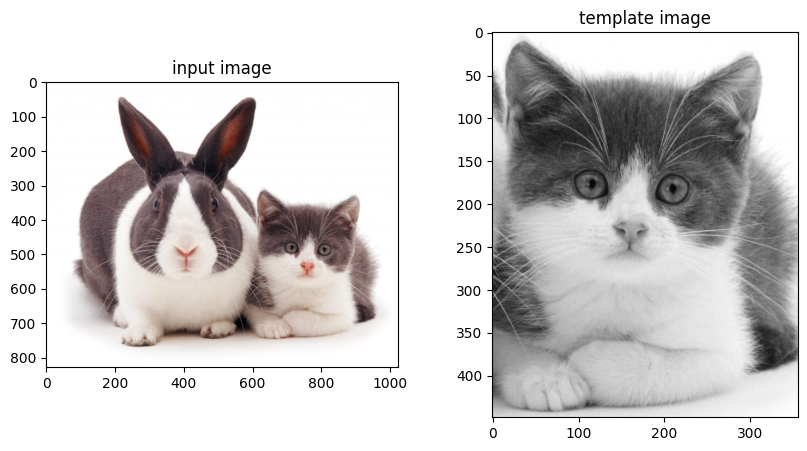

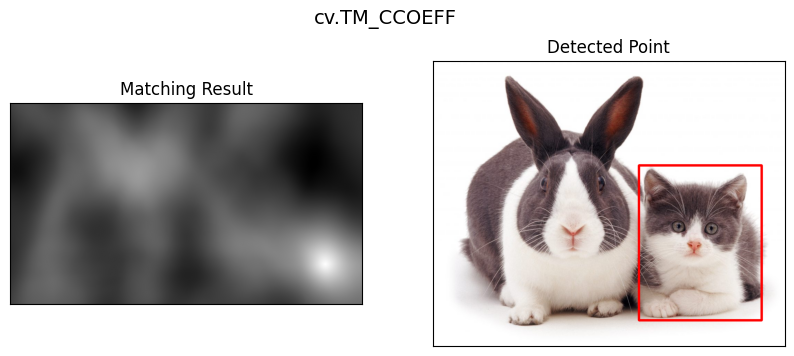

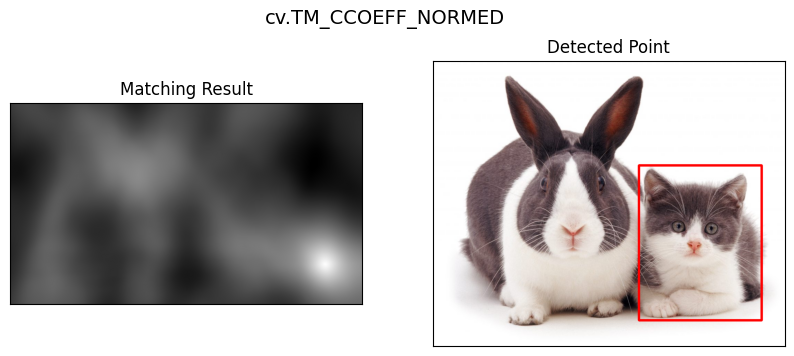

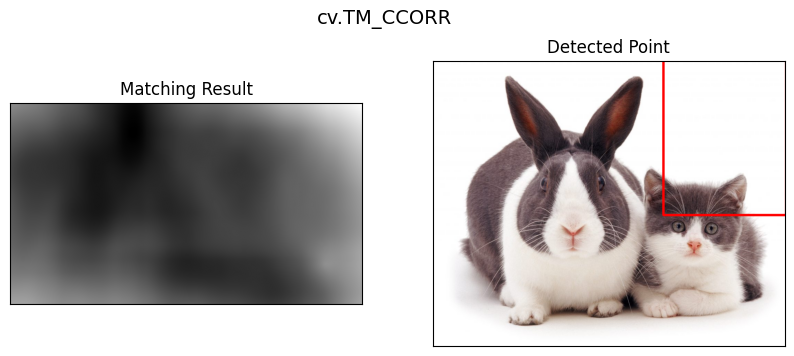

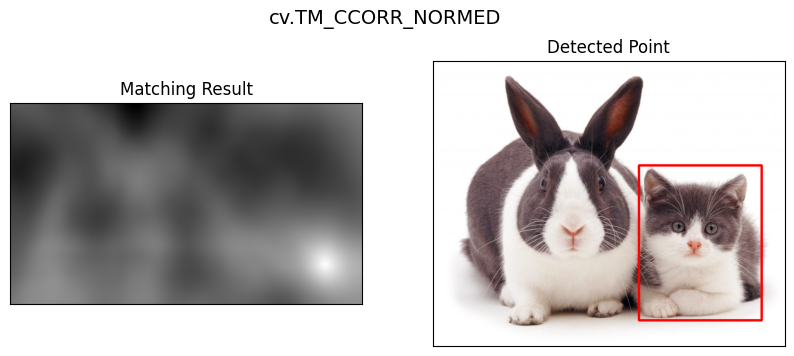

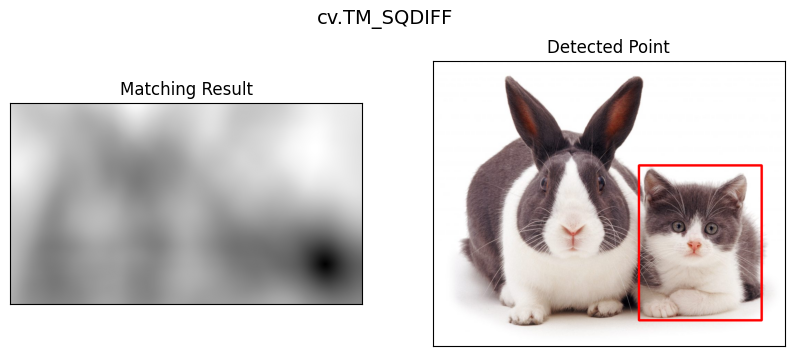

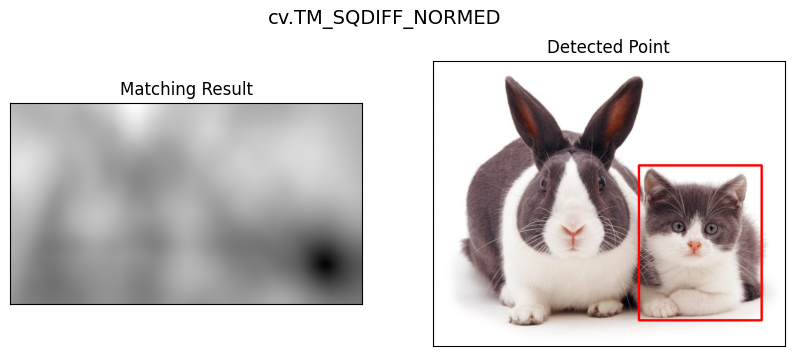

In [7]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

# Membaca citra input dan citra template
img_bgr = cv.imread(folder_path + 'cats_and_bunnies.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

template = cv.imread(folder_path + 'cat2_templatejpg.jpg', 0)
w, h = template.shape[::-1]

# Menampilkan Input Image dan Template Image berdampingan
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_rgb)
plt.title('input image')
plt.subplot(122), plt.imshow(template, cmap='gray')
plt.title('template image')
plt.show()

# Daftar 6 metode Template Matching di OpenCV
methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
           'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

# 3. Melakukan perulangan untuk menerapkan keenam metode
for meth in methods:
    img_display = img_rgb.copy()
    method = eval(meth)

    # Menerapkan template matching
    res = cv.matchTemplate(img_gray, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    # Jika metodenya TM_SQDIFF atau TM_SQDIFF_NORMED, ambil nilai minimum
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)

    # Menggambar kotak pembatas (bounding box) warna merah
    cv.rectangle(img_display, top_left, bottom_right, (255, 0, 0), 5)

    # Menampilkan hasil Matching Result dan Detected Point
    plt.figure(figsize=(10, 4))

    plt.subplot(121),
    plt.imshow(res, cmap='gray'),
    plt.title('Matching Result'),
    plt.xticks([]),
    plt.yticks([]),

    plt.subplot(122),
    plt.imshow(img_display),
    plt.title('Detected Point'),
    plt.xticks([]),
    plt.yticks([]),
    plt.suptitle(meth, fontsize=14)
    plt.show()

### **3. Implementasi Template Matching Tanpa Library OpenCV untuk Multiple Object**

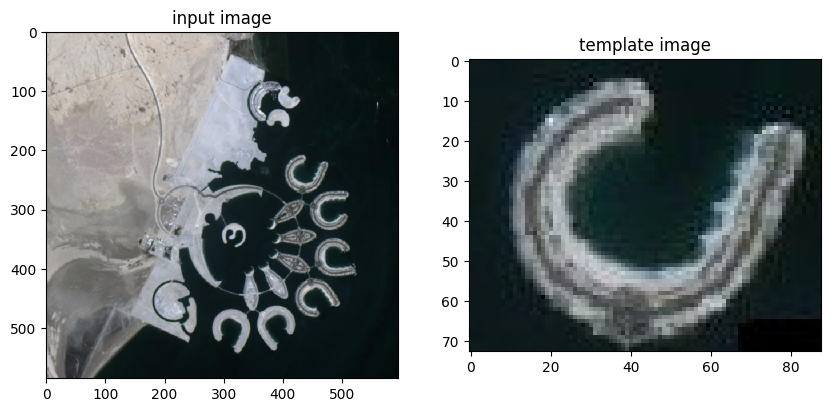

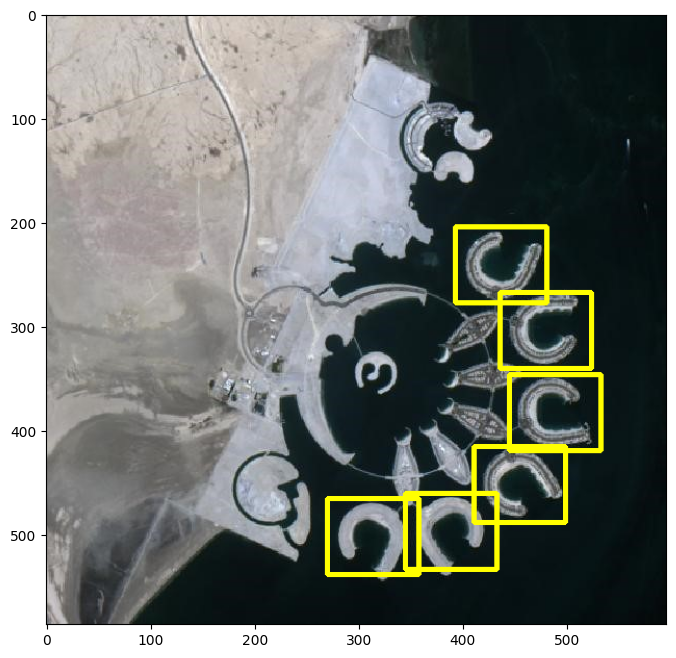

In [8]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

# Membaca dan menyiapkan citra input serta citra template
img_rgb = cv.cvtColor(cv.imread(folder_path + 'bahrain.jpg'), cv.COLOR_BGR2RGB)
temp_rgb = cv.cvtColor(cv.imread(folder_path + 'bahrain-template.jpg'), cv.COLOR_BGR2RGB)

img_gray = cv.cvtColor(img_rgb, cv.COLOR_RGB2GRAY).astype(float)
temp_gray = cv.cvtColor(temp_rgb, cv.COLOR_RGB2GRAY).astype(float)

# Menampilkan citra input dan citra template
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_rgb), plt.title('input image')
plt.subplot(122), plt.imshow(temp_rgb), plt.title('template image')
plt.show()

# Perhitungan manual Template Matching (Normalized Cross-Correlation)
H, W = img_gray.shape
h, w = temp_gray.shape
R = np.zeros((H - h + 1, W - w + 1))

temp_diff = temp_gray - np.mean(temp_gray)
temp_norm = np.linalg.norm(temp_diff)

for y in range(H - h + 1):
    for x in range(W - w + 1):
        patch_diff = img_gray[y:y+h, x:x+w] - np.mean(img_gray[y:y+h, x:x+w])
        patch_norm = np.linalg.norm(patch_diff)

        if patch_norm > 0:
            R[y, x] = np.sum(temp_diff * patch_diff) / (temp_norm * patch_norm)

# Menyeleksi 6 koordinat terbaik menggunakan Non-Maximum Suppression (NMS)
R[:180, :] = -1  # Abaikan area daratan atas
R[:, :250] = -1  # Abaikan area daratan kiri

img_result = img_rgb.copy()
nms_h, nms_w = int(h * 0.65), int(w * 0.65)

for _ in range(6):
    y_max, x_max = np.unravel_index(np.argmax(R), R.shape)

    # Menggambar kotak pembatas warna kuning pada titik terpilih
    cv.rectangle(img_result, (x_max, y_max), (x_max + w, y_max + h), (255, 255, 0), 3)

    # Menghapus nilai di sekitar titik terpilih agar objek yang sama tidak terdeteksi ulang
    R[max(0, y_max - nms_h):min(R.shape[0], y_max + nms_h),
      max(0, x_max - nms_w):min(R.shape[1], x_max + nms_w)] = -1

# Menampilkan hasil akhir deteksi objek
plt.figure(figsize=(8, 8))
plt.imshow(img_result)
plt.show()

### **4. Implementasi Metode Edge Detection (Sobel, Canny, dan Laplacian)**

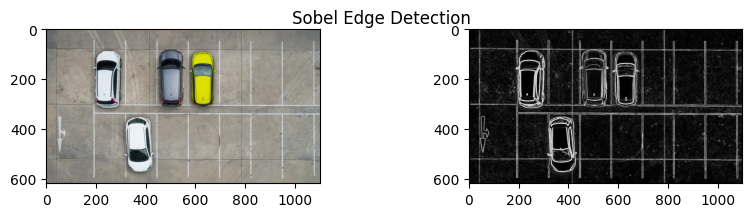

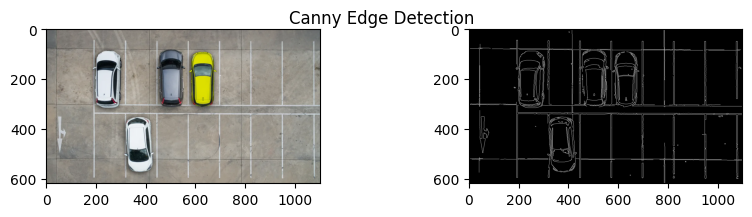

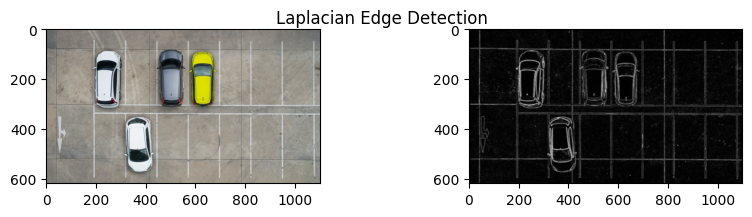

In [9]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

img_bgr = cv.imread(folder_path + 'car-park.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

img_blur = cv.GaussianBlur(img_gray, (3, 3), 0)

# Sobel Edge Detection
sobel_x = cv.Sobel(img_blur, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(img_blur, cv.CV_64F, 0, 1, ksize=3)
sobel_combined = cv.magnitude(sobel_x, sobel_y)
sobel_edges = cv.convertScaleAbs(sobel_combined)

plt.figure(figsize=(10, 2))
plt.suptitle('Sobel Edge Detection')
plt.subplot(121), plt.imshow(img_rgb)
plt.subplot(122), plt.imshow(sobel_edges, cmap='gray')
plt.show()

# Canny Edge Detection
canny_edges = cv.Canny(img_blur, 100, 200)

plt.figure(figsize=(10, 2))
plt.suptitle('Canny Edge Detection')
plt.subplot(121), plt.imshow(img_rgb)
plt.subplot(122), plt.imshow(canny_edges, cmap='gray')
plt.show()

# Laplacian Edge Detection
laplacian = cv.Laplacian(img_blur, cv.CV_64F, ksize=3)
laplacian_edges = cv.convertScaleAbs(laplacian)

plt.figure(figsize=(10, 2))
plt.suptitle('Laplacian Edge Detection')
plt.subplot(121), plt.imshow(img_rgb)
plt.subplot(122), plt.imshow(laplacian_edges, cmap='gray')
plt.show()

### **5. Implementasi Metode Corner Detection (Harris dan Shi-Tomasi)**

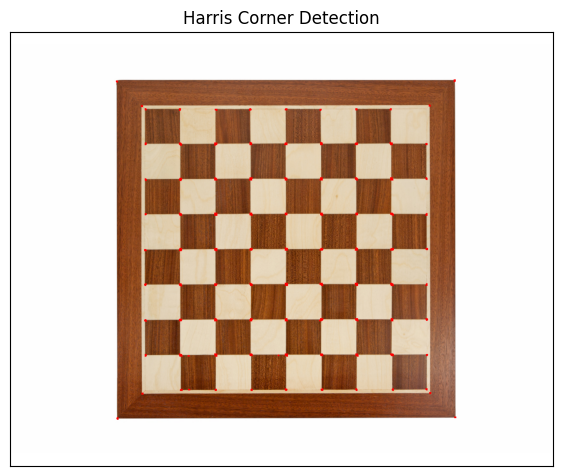

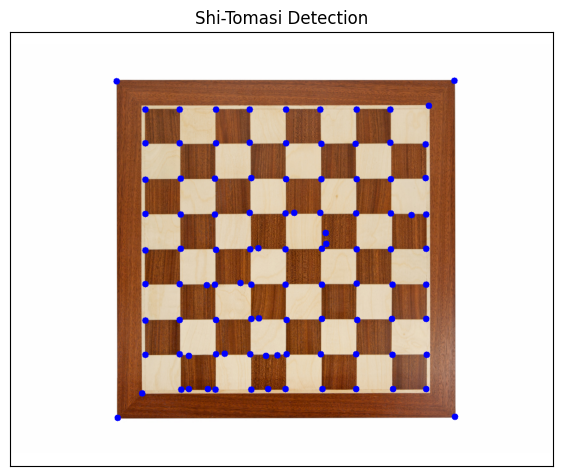

In [10]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

img_bgr = cv.imread(folder_path + 'chess-board.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Harris Corner Detection
img_harris = img_rgb.copy()
gray_float = np.float32(img_gray)

dst = cv.cornerHarris(gray_float, 2, 3, 0.04)

# Dilasi hasil corner agar titik sudut merah terlihat lebih jelas
dst = cv.dilate(dst, None)

# Menandai sudut yang melebihi threshold
img_harris[dst > 0.01 * dst.max()] = [255, 0, 0]

plt.figure(figsize=(7, 7))
plt.title('Harris Corner Detection')
plt.imshow(img_harris)
plt.xticks([]), plt.yticks([])
plt.show()



# Shi-Tomasi Detection
img_shitomasi = img_rgb.copy()

corners = cv.goodFeaturesToTrack(img_gray, 100, 0.01, 10)
corners = np.intp(corners)

# Menggambar titik lingkaran biru pada setiap sudut yang ditemukan
for i in corners:
    x, y = i.ravel()
    cv.circle(img_shitomasi, (x, y), 6, (0, 0, 255), -1)

plt.figure(figsize=(7, 7))
plt.title('Shi-Tomasi Detection')
plt.imshow(img_shitomasi)
plt.xticks([]), plt.yticks([])
plt.show()

### **6. Implementasi Grid Detection dengan Metode Hough Transform**

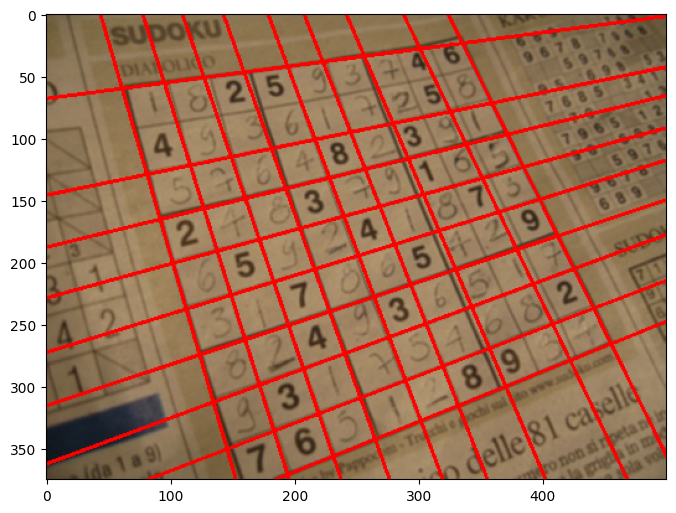

In [11]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

img_bgr = cv.imread(folder_path + 'sudoku.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

img_blur = cv.GaussianBlur(img_gray, (5, 5), 0)

# Canny Edge Detection
edges = cv.Canny(img_blur, 50, 150, apertureSize=3)

# HoughLines
lines = cv.HoughLines(edges, 1, np.pi / 180, 110)

# Filter garis duplikat
def filter_lines(lines, rho_thresh=20, theta_thresh=np.deg2rad(8)):
    if lines is None:
        return []
    lines = [l[0] for l in lines]
    groups = []
    for rho, theta in lines:
        placed = False
        for g in groups:
            g_rho, g_theta = np.mean(g, axis=0)
            if abs(rho - g_rho) < rho_thresh and abs(theta - g_theta) < theta_thresh:
                g.append((rho, theta))
                placed = True
                break
        if not placed:
            groups.append([(rho, theta)])
    return [tuple(np.mean(g, axis=0)) for g in groups]

filtered = filter_lines(lines)

# Menggambar garis merah hasil Hough Transform pada citra
img_hough = img_rgb.copy()
for rho, theta in filtered:
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv.line(img_hough, (x1, y1), (x2, y2), (255, 0, 0), 2)

# Menampilkan hasil gambar
plt.figure(figsize=(8, 8))
plt.imshow(img_hough)
plt.show()

### **7. Implementasi Contour Detection**

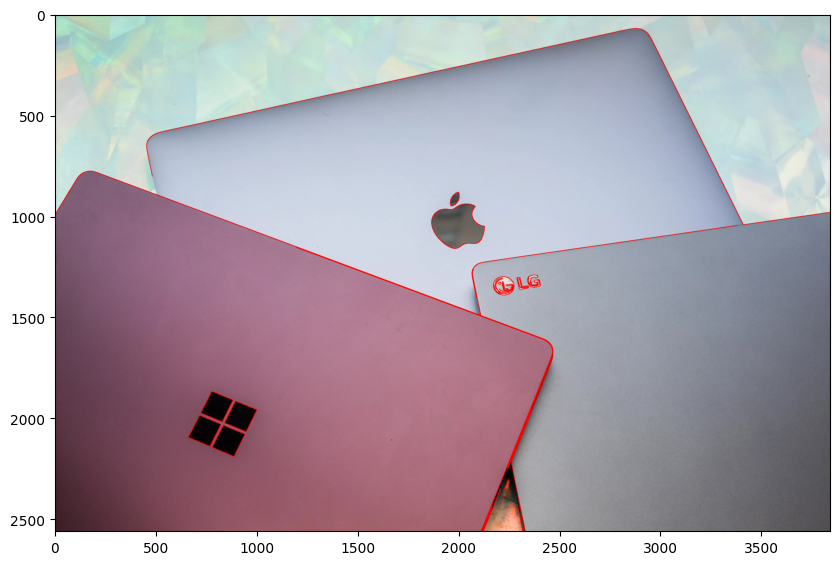

In [12]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

img_bgr = cv.imread(folder_path + 'laptop.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Mengubah citra menjadi citra biner menggunakan Canny Edge Detection
img_blur = cv.GaussianBlur(img_gray, (5, 5), 0)
edges = cv.Canny(img_blur, 50, 150)

# Menemukan kontur menggunakan cv.findContours()
contours, hierarchy = cv.findContours(edges, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

# Menggambarkan kontur
img_contour = img_rgb.copy()
cv.drawContours(img_contour, contours, -1, (255, 0, 0), 2)

# 5. Menampilkan hasil akhir Contour Detection
plt.figure(figsize=(10, 10))
plt.imshow(img_contour)
plt.show()

# **D2. Praktikum Feature Matching dan Face Detection**

### **8. Face Detection Menggunakan Haar Cascades**

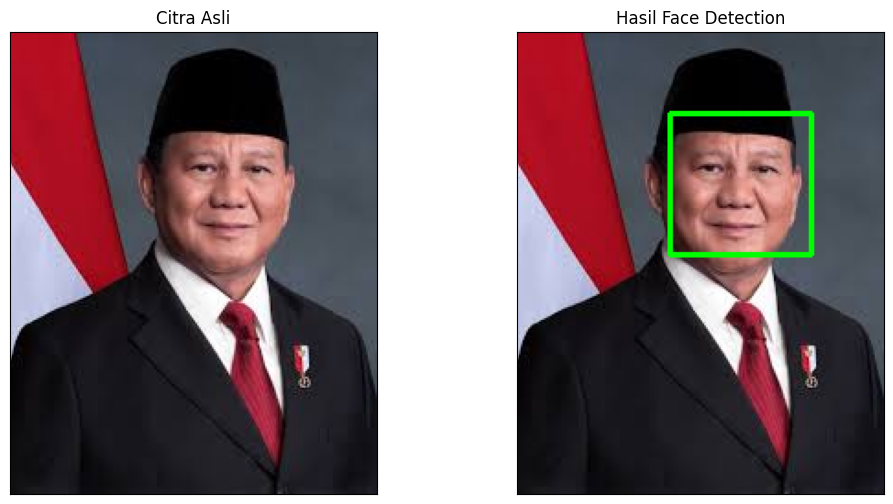

In [33]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

# Memuat model pretrained Haar Cascade untuk wajah
cascade_wajah = cv.CascadeClassifier(folder_path + '/haarcascades/haarcascade_frontalface_alt.xml')

img_bgr = cv.imread(folder_path + 'prabowo.jpg')
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Mendeteksi koordinat wilayah wajah (roi_wajah)
roi_wajah = cascade_wajah.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=5)

# Menggambar kotak berwarna hijau di sekeliling wajah yang terdeteksi
img_result = img_bgr.copy()
for (x, y, w, h) in roi_wajah:
    cv.rectangle(img_result, (x, y), (x + w, y + h), (0, 255, 0), 2)

img_asli_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_result_rgb = cv.cvtColor(img_result, cv.COLOR_BGR2RGB)


plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_asli_rgb)
plt.title('Citra Asli')
plt.xticks([]), plt.yticks([])

plt.subplot(1, 2, 2)
plt.imshow(img_result_rgb)
plt.title('Hasil Face Detection')
plt.xticks([]), plt.yticks([])

plt.show()

### **9. Face Detection pada Wajah Kucing**

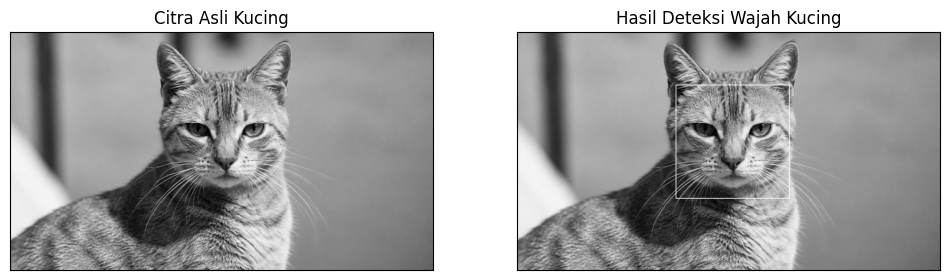

In [29]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

# Memuat model pretrained Haar Cascade khusus wajah kucing
cascade_kucing = cv.CascadeClassifier(folder_path + '/haarcascades/haarcascade_frontalcatface.xml')

img_bgr = cv.imread(folder_path + 'cat.png')
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# 3. Mendeteksi koordinat wilayah wajah kucing
roi_kucing = cascade_kucing.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=3)

# 4. Menggambar kotak berwarna putih di sekeliling wajah kucing yang terdeteksi
img_result = img_bgr.copy()
for (x, y, w, h) in roi_kucing:
    cv.rectangle(img_result, (x, y), (x + w, y + h), (255, 255, 255), 2)


img_asli_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_result_rgb = cv.cvtColor(img_result, cv.COLOR_BGR2RGB)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_asli_rgb)
plt.title('Citra Asli Kucing')
plt.xticks([]), plt.yticks([])

plt.subplot(1, 2, 2)
plt.imshow(img_result_rgb)
plt.title('Hasil Deteksi Wajah Kucing')
plt.xticks([]), plt.yticks([])

plt.show()

### **10. Eyes Detection pada Wajah Pak Prabowo**

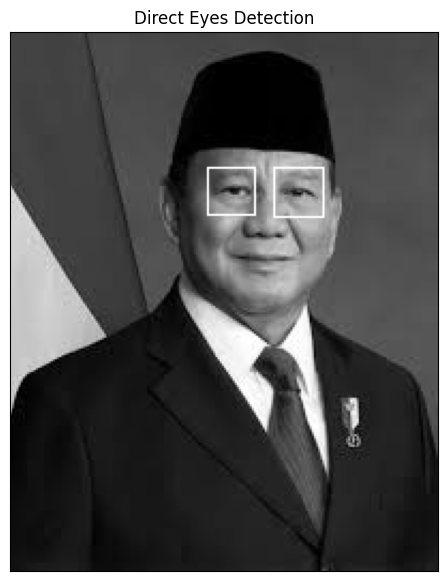

In [40]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

# Memuat model pretrained Haar Cascade untuk wajah dan mata
cascade_wajah = cv.CascadeClassifier(folder_path + '/haarcascades/haarcascade_frontalface_alt.xml')
cascade_mata = cv.CascadeClassifier(folder_path + '/haarcascades/haarcascade_eye.xml')

img_bgr = cv.imread(folder_path + 'prabowo.jpg')
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Mendeteksi wilayah wajah
roi_wajah = cascade_wajah.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=5)

img_result = img_bgr.copy()

# 4. Mendeteksi mata di dalam area wajah
for (x, y, w, h) in roi_wajah:
    roi_gray = img_gray[y:y+h, x:x+w]
    roi_color = img_result[y:y+h, x:x+w]

    mata = cascade_mata.detectMultiScale(roi_gray, scaleFactor=1.1, minNeighbors=1)
    for (ex, ey, ew, eh) in mata:
        cv.rectangle(roi_color, (ex, ey), (ex + ew, ey + eh), (255, 255, 255), 1)


img_result_gray = cv.cvtColor(img_result, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(7, 7))
plt.imshow(img_result_gray, cmap='gray')
plt.title('Direct Eyes Detection')
plt.xticks([]), plt.yticks([])
plt.show()

### **11. Deteksi Senyuman pada Gambar People**

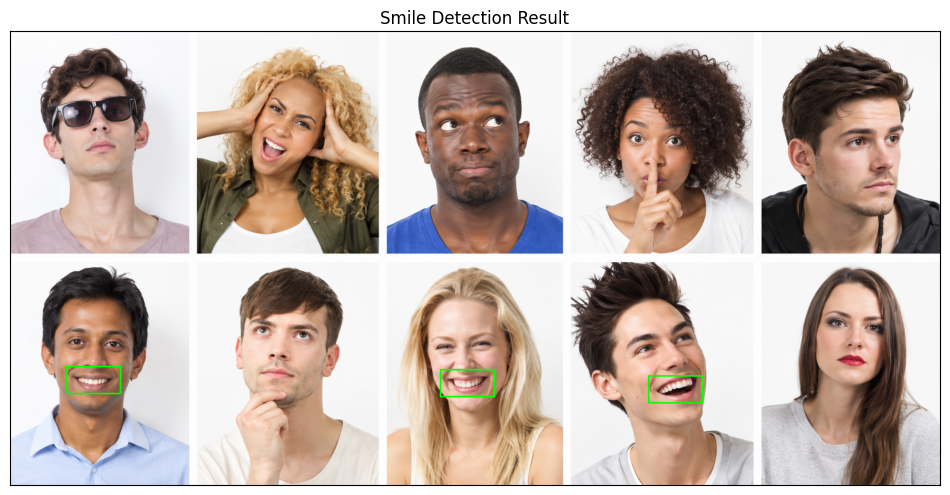

In [44]:
folder_path = '/content/drive/MyDrive/Semester 5/PCVK/images/Images Object Detection/'

# Memuat model pretrained Haar Cascade untuk wajah dan senyuman
cascade_wajah = cv.CascadeClassifier(folder_path + '/haarcascades/haarcascade_frontalface_alt.xml')
cascade_senyum = cv.CascadeClassifier(folder_path + '/haarcascades/haarcascade_smile.xml')

img_bgr = cv.imread(folder_path + 'people.png')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Mendeteksi wajah terlebih dahulu agar pencarian senyuman fokus di area wajah
wajah = cascade_wajah.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=3)

img_result = img_rgb.copy()

for (x, y, w, h) in wajah:
    # Mengambil ROI bagian bawah wajah tempat mulut berada
    roi_gray = img_gray[y:y+h, x:x+w]
    roi_color = img_result[y:y+h, x:x+w]

    # Mendeteksi senyuman di dalam area wajah
    senyum = cascade_senyum.detectMultiScale(roi_gray, scaleFactor=1.7, minNeighbors=5)

    for (sx, sy, sw, sh) in senyum:
        cv.rectangle(roi_color, (sx, sy), (sx + sw, sy + sh), (0, 255, 0), 2)

plt.figure(figsize=(12, 8))
plt.imshow(img_result)
plt.title('Smile Detection')
plt.xticks([]), plt.yticks([])
plt.show()

### **12. Face Tracking**